In [11]:
# ============================================================
# CELL 1: IMPORTS AND LOAD EVALUATION RESULTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE_DIR = Path(r"D:\Air-Pollution\datasets\processed\model_results")

summary = pd.read_csv(BASE_DIR / "evaluation_summary.csv")
borough = pd.read_csv(BASE_DIR / "evaluation_by_borough.csv")
year = pd.read_csv(BASE_DIR / "evaluation_by_year.csv")
rolling = pd.read_csv(BASE_DIR / "evaluation_rolling_backtest.csv")
predictions = pd.read_csv(BASE_DIR / "evaluation_predictions.csv")

display(Markdown("# NYC Air Quality Prediction Results"))
display(Markdown("""
This notebook summarizes the performance of the Random Forest, XGBoost,
and no-change baseline models. It includes overall metrics, rolling-origin
backtesting, borough-level performance, and prediction analysis.
"""))

# NYC Air Quality Prediction Results


This notebook summarizes the performance of the Random Forest, XGBoost,
and no-change baseline models. It includes overall metrics, rolling-origin
backtesting, borough-level performance, and prediction analysis.


In [12]:
# ============================================================
# CELL 2: EXPERIMENT OVERVIEW
# ============================================================

display(Markdown("## 1. Experiment Overview"))

display(Markdown("""
Two feature sets were evaluated:

- **Historical Core:** Uses previously observed AQI, NOx emissions, and traffic data.
- **Extended:** Uses previously observed AQI, tree plantings, commuting data,
  NOx emissions, and weather features.

The models predict the following year's median AQI for each NYC borough.

The no-change baseline predicts that the next year's AQI will equal the
most recently observed AQI.
"""))

print("Evaluation summary:")
display(summary)

## 1. Experiment Overview


Two feature sets were evaluated:

- **Historical Core:** Uses previously observed AQI, NOx emissions, and traffic data.
- **Extended:** Uses previously observed AQI, tree plantings, commuting data,
  NOx emissions, and weather features.

The models predict the following year's median AQI for each NYC borough.

The no-change baseline predicts that the next year's AQI will equal the
most recently observed AQI.


Evaluation summary:


,experiment,split,model,n_rows,MAE,RMSE,R2,baseline_MAE,MAE_improvement_vs_baseline_pct
0,Extended features,rolling_backtest,No-change baseline,15.0,3.733333,4.195235,-0.275773,3.733333,0.000000
1,Extended features,rolling_backtest,Random Forest,15.0,2.975969,3.555117,0.083846,3.733333,20.286555
2,Extended features,rolling_backtest,XGBoost,15.0,3.121924,3.729647,-0.008315,3.733333,16.377047
3,Extended features,test,No-change baseline,10.0,4.000000,4.560702,-0.756757,4.000000,0.000000
4,Extended features,test,Random Forest,10.0,2.741704,3.417532,0.013554,4.000000,31.457391
5,Extended features,test,XGBoost,10.0,2.461100,3.130784,0.172145,4.000000,38.472509
6,Extended features,validation,No-change baseline,5.0,3.200000,3.346640,-0.590909,3.200000,0.000000
7,Extended features,validation,Random Forest,5.0,3.827100,4.345203,-1.681930,3.200000,-19.596883
8,Extended features,validation,XGBoost,5.0,4.199155,4.832061,-2.316593,3.200000,-31.223583
9,Historical core,rolling_backtest,No-change baseline,30.0,3.433333,4.246567,-0.133063,3.433333,0.000000


## 2. Overall Model Performance


The primary evaluation metrics are:

- **MAE:** Average absolute prediction error. Lower is better.
- **RMSE:** Penalizes larger prediction errors more heavily. Lower is better.
- **R²:** Measures how much variation in the target is explained by the model.
- **MAE Improvement:** Percentage improvement over the no-change baseline.


,experiment,split,model,n_rows,MAE,RMSE,R2,baseline_MAE,MAE_improvement_vs_baseline_pct
1,Extended features,rolling_backtest,Random Forest,15.0,2.975969,3.555117,0.083846,3.733333,20.286555
2,Extended features,rolling_backtest,XGBoost,15.0,3.121924,3.729647,-0.008315,3.733333,16.377047
0,Extended features,rolling_backtest,No-change baseline,15.0,3.733333,4.195235,-0.275773,3.733333,0.000000
5,Extended features,test,XGBoost,10.0,2.461100,3.130784,0.172145,4.000000,38.472509
4,Extended features,test,Random Forest,10.0,2.741704,3.417532,0.013554,4.000000,31.457391
3,Extended features,test,No-change baseline,10.0,4.000000,4.560702,-0.756757,4.000000,0.000000
6,Extended features,validation,No-change baseline,5.0,3.200000,3.346640,-0.590909,3.200000,0.000000
7,Extended features,validation,Random Forest,5.0,3.827100,4.345203,-1.681930,3.200000,-19.596883
8,Extended features,validation,XGBoost,5.0,4.199155,4.832061,-2.316593,3.200000,-31.223583
11,Historical core,rolling_backtest,XGBoost,30.0,3.078515,3.724481,0.128415,3.433333,10.334507


### MAE Comparison: rolling_backtest

experiment,Extended features,Historical core
model,,
No-change baseline,3.733333,3.433333
Random Forest,2.975969,3.338673
XGBoost,3.121924,3.078515


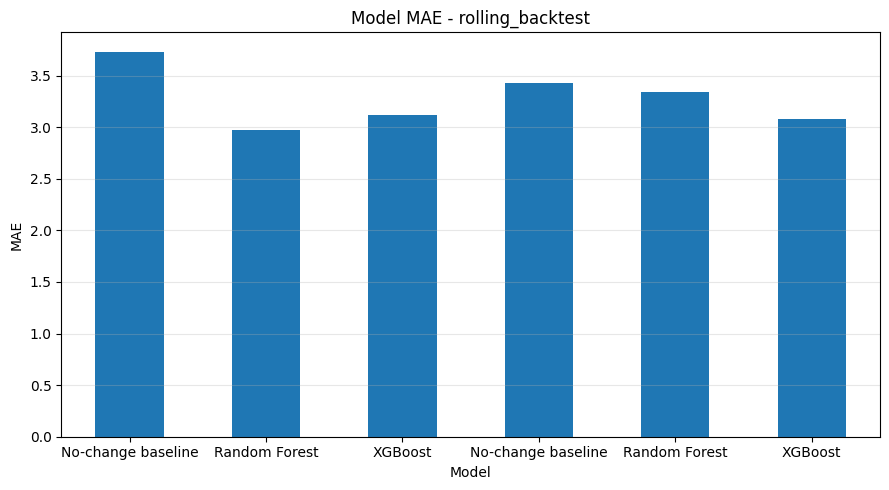

### MAE Comparison: test

experiment,Extended features,Historical core
model,,
No-change baseline,4.000000,4.000000
Random Forest,2.741704,3.639189
XGBoost,2.461100,3.127158


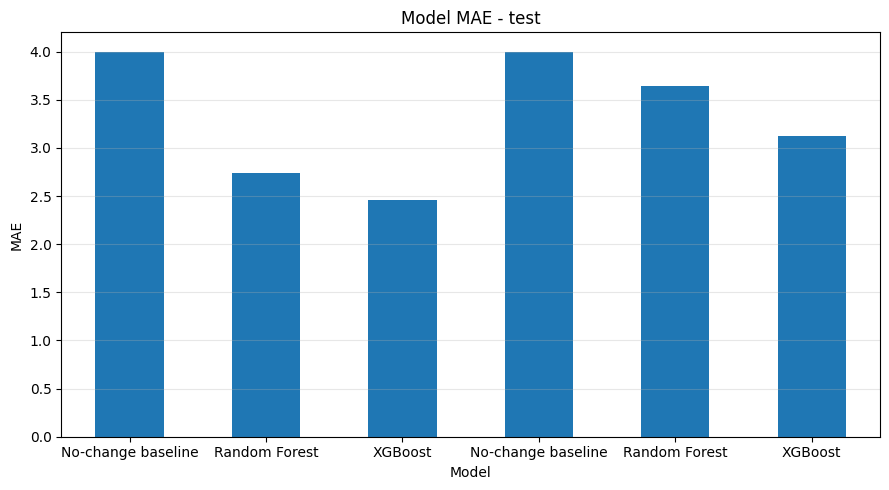

### MAE Comparison: validation

experiment,Extended features,Historical core
model,,
No-change baseline,3.200000,2.200000
Random Forest,3.827100,2.233675
XGBoost,4.199155,2.002544


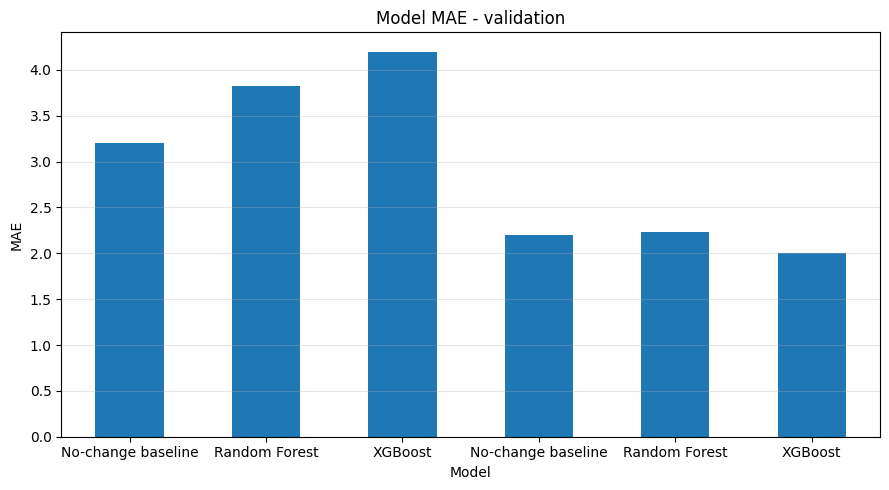

In [13]:
# ============================================================
# CELL 3: OVERALL MODEL PERFORMANCE
# ============================================================

display(Markdown("## 2. Overall Model Performance"))

display(Markdown("""
The primary evaluation metrics are:

- **MAE:** Average absolute prediction error. Lower is better.
- **RMSE:** Penalizes larger prediction errors more heavily. Lower is better.
- **R²:** Measures how much variation in the target is explained by the model.
- **MAE Improvement:** Percentage improvement over the no-change baseline.
"""))

display(summary.sort_values(["experiment", "split", "MAE"]))

for split_name in summary["split"].dropna().unique():
    subset = summary[summary["split"] == split_name]

    if subset.empty:
        continue

    display(Markdown(f"### MAE Comparison: {split_name}"))

    pivot = subset.pivot_table(
        index="model",
        columns="experiment",
        values="MAE",
        aggfunc="mean"
    )

    display(pivot)

    ax = subset.plot(
        kind="bar",
        x="model",
        y="MAE",
        figsize=(9, 5),
        title=f"Model MAE - {split_name}",
        legend=False
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("MAE")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 3. Rolling-Origin Backtesting


Rolling-origin backtesting evaluates models across multiple forecast years.
For each fold, the model is trained using only data available before the
prediction year.

This provides a more realistic assessment of how the models may perform
when predicting future AQI values.


,experiment,split,model,n_rows,MAE,RMSE,R2,baseline_MAE,MAE_improvement_vs_baseline_pct
0,Extended features,rolling_backtest,No-change baseline,15.0,3.733333,4.195235,-0.275773,3.733333,0.000000
1,Extended features,rolling_backtest,Random Forest,15.0,2.975969,3.555117,0.083846,3.733333,20.286555
2,Extended features,rolling_backtest,XGBoost,15.0,3.121924,3.729647,-0.008315,3.733333,16.377047
3,Historical core,rolling_backtest,No-change baseline,30.0,3.433333,4.246567,-0.133063,3.433333,0.000000
4,Historical core,rolling_backtest,Random Forest,30.0,3.338673,3.912937,0.037980,3.433333,2.757109
5,Historical core,rolling_backtest,XGBoost,30.0,3.078515,3.724481,0.128415,3.433333,10.334507


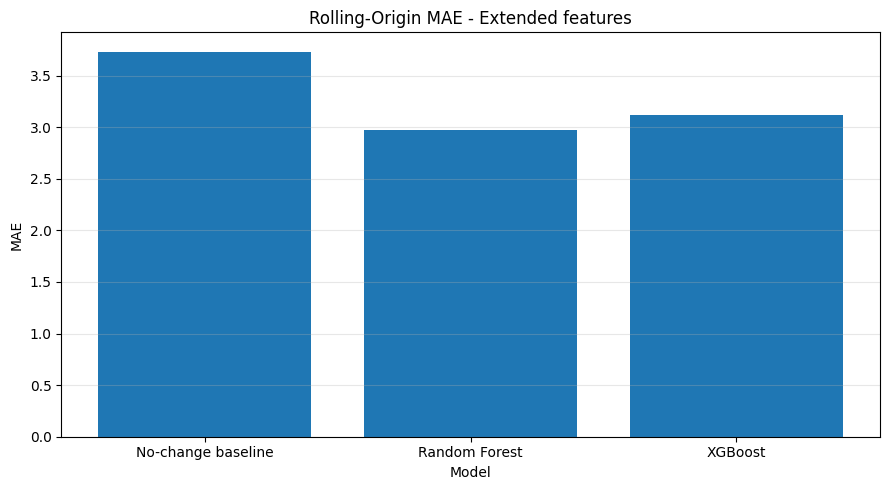

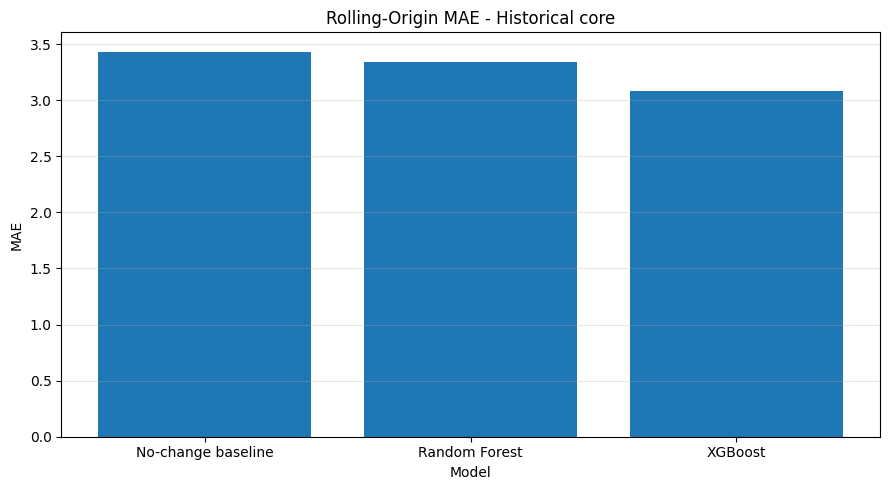

In [14]:
# ============================================================
# CELL 4: ROLLING-ORIGIN BACKTESTING
# ============================================================

display(Markdown("## 3. Rolling-Origin Backtesting"))

display(Markdown("""
Rolling-origin backtesting evaluates models across multiple forecast years.
For each fold, the model is trained using only data available before the
prediction year.

This provides a more realistic assessment of how the models may perform
when predicting future AQI values.
"""))

display(rolling)

for experiment_name in rolling["experiment"].dropna().unique():
    subset = rolling[rolling["experiment"] == experiment_name]

    plt.figure(figsize=(9, 5))

    plt.bar(
        subset["model"],
        subset["MAE"]
    )

    plt.title(f"Rolling-Origin MAE - {experiment_name}")
    plt.xlabel("Model")
    plt.ylabel("MAE")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Performance by Forecast Year


Year-level evaluation helps identify whether model performance is consistent
across different prediction years.

A model may perform well overall while struggling during particular years.


,experiment,split,target_year,model,n_rows,MAE,RMSE,R2,baseline_MAE,MAE_improvement_vs_baseline_pct
0,Extended features,rolling_backtest,2023,No-change baseline,5.0,3.200000,3.346640,-0.590909,3.2,0.000000
1,Extended features,rolling_backtest,2023,Random Forest,5.0,3.810839,4.372186,-1.715342,3.2,-19.088724
2,Extended features,rolling_backtest,2023,XGBoost,5.0,4.180676,4.834632,-2.320124,3.2,-30.646110
3,Extended features,rolling_backtest,2024,No-change baseline,5.0,5.200000,5.291503,-3.216867,5.2,0.000000
4,Extended features,rolling_backtest,2024,Random Forest,5.0,2.897483,3.509808,-0.855234,5.2,44.279182
5,Extended features,rolling_backtest,2024,XGBoost,5.0,2.696782,3.240118,-0.581079,5.2,48.138809
6,Extended features,rolling_backtest,2025,No-change baseline,5.0,2.800000,3.687818,0.039548,2.8,0.000000
7,Extended features,rolling_backtest,2025,Random Forest,5.0,2.219584,2.545940,0.542245,2.8,20.729138
8,Extended features,rolling_backtest,2025,XGBoost,5.0,2.488313,2.803351,0.445002,2.8,11.131668
9,Extended features,test,2024,No-change baseline,5.0,5.200000,5.291503,-3.216867,5.2,0.000000


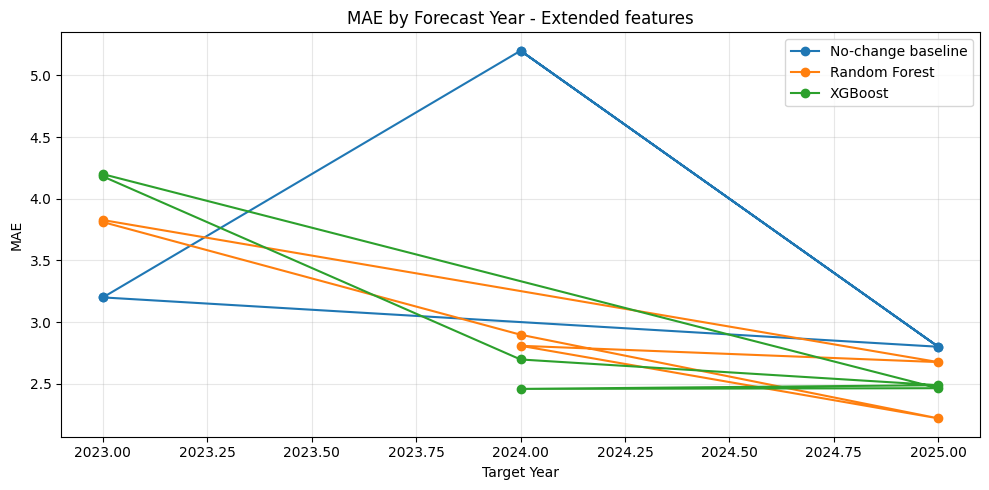

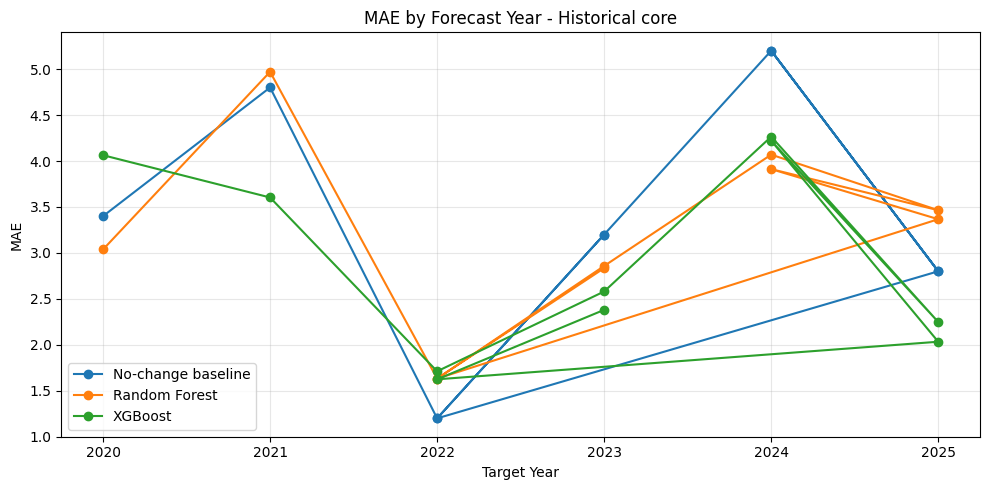

In [15]:
# ============================================================
# CELL 5: PERFORMANCE BY FORECAST YEAR
# ============================================================

display(Markdown("## 4. Performance by Forecast Year"))

display(Markdown("""
Year-level evaluation helps identify whether model performance is consistent
across different prediction years.

A model may perform well overall while struggling during particular years.
"""))

display(year)

for experiment_name in year["experiment"].dropna().unique():
    subset = year[year["experiment"] == experiment_name]

    plt.figure(figsize=(10, 5))

    for model_name in subset["model"].dropna().unique():
        model_data = subset[subset["model"] == model_name]

        plt.plot(
            model_data["target_year"],
            model_data["MAE"],
            marker="o",
            label=model_name
        )

    plt.title(f"MAE by Forecast Year - {experiment_name}")
    plt.xlabel("Target Year")
    plt.ylabel("MAE")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 5. Performance by NYC Borough


Borough-level MAE shows how prediction accuracy differs across the five
NYC boroughs.

These values should be interpreted cautiously because each borough has
a relatively small number of evaluation observations.


,experiment,split,borough,model,n_rows,MAE,RMSE,R2,baseline_MAE,MAE_improvement_vs_baseline_pct
0,Extended features,rolling_backtest,Bronx,No-change baseline,3.0,3.666667,3.785939,-2.394737,3.666667,0.000000
1,Extended features,rolling_backtest,Bronx,Random Forest,3.0,2.626066,2.683924,-0.706080,3.666667,28.380020
2,Extended features,rolling_backtest,Bronx,XGBoost,3.0,2.876891,2.947408,-1.057497,3.666667,21.539341
3,Extended features,rolling_backtest,Brooklyn,No-change baseline,3.0,3.333333,4.396969,-0.775510,3.333333,0.000000
4,Extended features,rolling_backtest,Brooklyn,Random Forest,3.0,3.910470,4.066313,-0.518512,3.333333,-17.314098
...,...,...,...,...,...,...,...,...,...,...
85,Historical core,validation,Queens,Random Forest,2.0,2.569583,2.854131,-2.620472,1.500000,-71.305528
86,Historical core,validation,Queens,XGBoost,2.0,1.359852,1.751161,-0.362918,1.500000,9.343211
87,Historical core,validation,Staten Island,No-change baseline,2.0,2.000000,2.000000,-3.000000,2.000000,0.000000
88,Historical core,validation,Staten Island,Random Forest,2.0,0.671166,0.806464,0.349616,2.000000,66.441678


### Borough MAE - Extended features

model,No-change baseline,Random Forest,XGBoost
borough,,,
Bronx,3.555556,2.652131,2.851556
Brooklyn,3.277778,3.593195,3.709280
Manhattan,5.555556,4.806210,4.595863
Queens,3.000000,2.996719,3.574475
Staten Island,2.833333,1.859700,1.572456


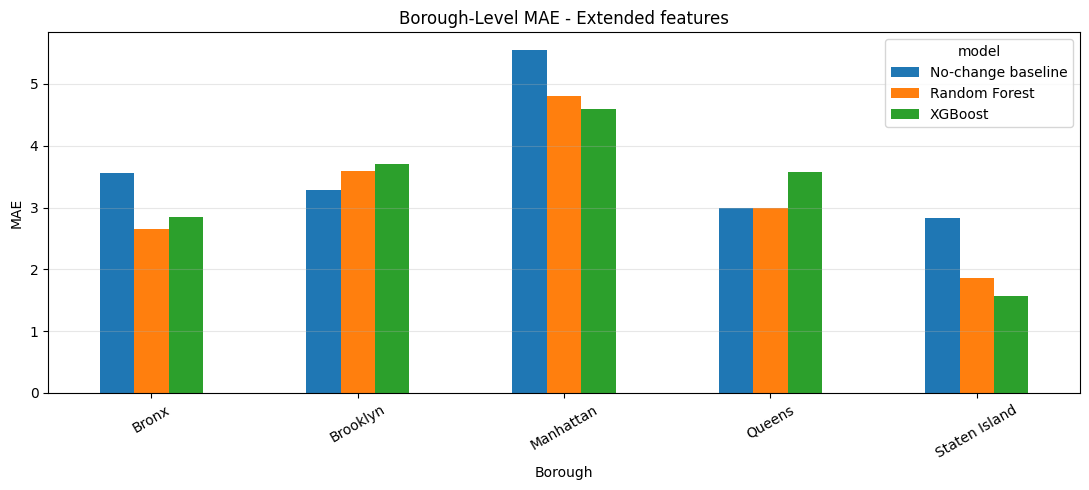

### Borough MAE - Historical core

model,No-change baseline,Random Forest,XGBoost
borough,,,
Bronx,3.277778,3.378698,3.053802
Brooklyn,3.444444,3.716158,3.584381
Manhattan,4.277778,3.915328,3.700609
Queens,2.333333,2.578321,1.979189
Staten Island,2.722222,1.764057,1.362382


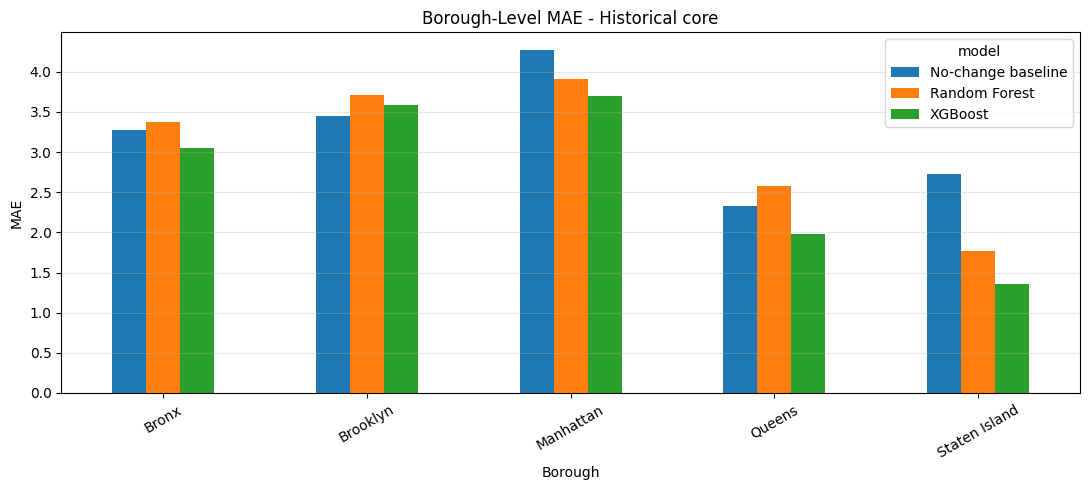

In [16]:
# ============================================================
# CELL 6: PERFORMANCE BY NYC BOROUGH
# ============================================================

display(Markdown("## 5. Performance by NYC Borough"))

display(Markdown("""
Borough-level MAE shows how prediction accuracy differs across the five
NYC boroughs.

These values should be interpreted cautiously because each borough has
a relatively small number of evaluation observations.
"""))

display(borough)

for experiment_name in borough["experiment"].dropna().unique():
    subset = borough[borough["experiment"] == experiment_name]

    pivot = subset.pivot_table(
        index="borough",
        columns="model",
        values="MAE",
        aggfunc="mean"
    )

    display(Markdown(f"### Borough MAE - {experiment_name}"))
    display(pivot)

    pivot.plot(
        kind="bar",
        figsize=(11, 5),
        title=f"Borough-Level MAE - {experiment_name}"
    )

    plt.xlabel("Borough")
    plt.ylabel("MAE")
    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 6. Actual vs. Predicted AQI


These plots compare predicted AQI values against the actual observed values.

Predictions closer to the diagonal reference line indicate better performance.


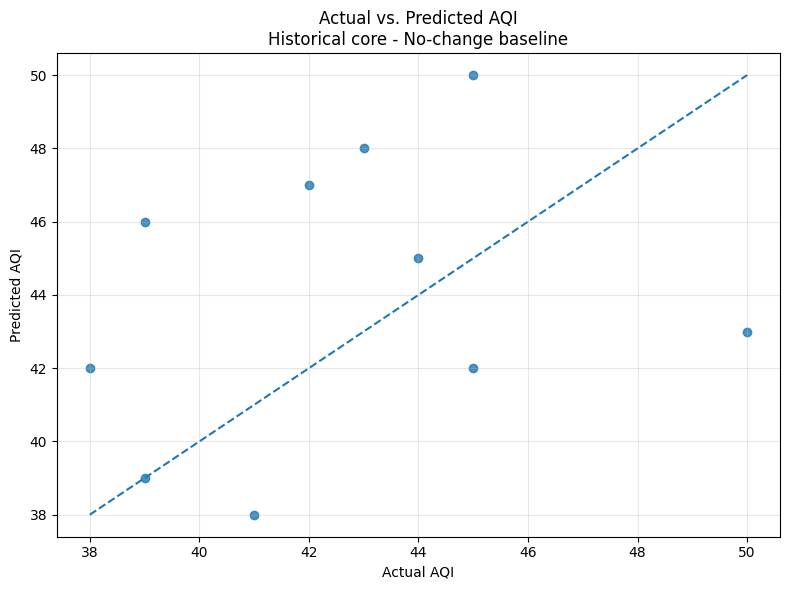

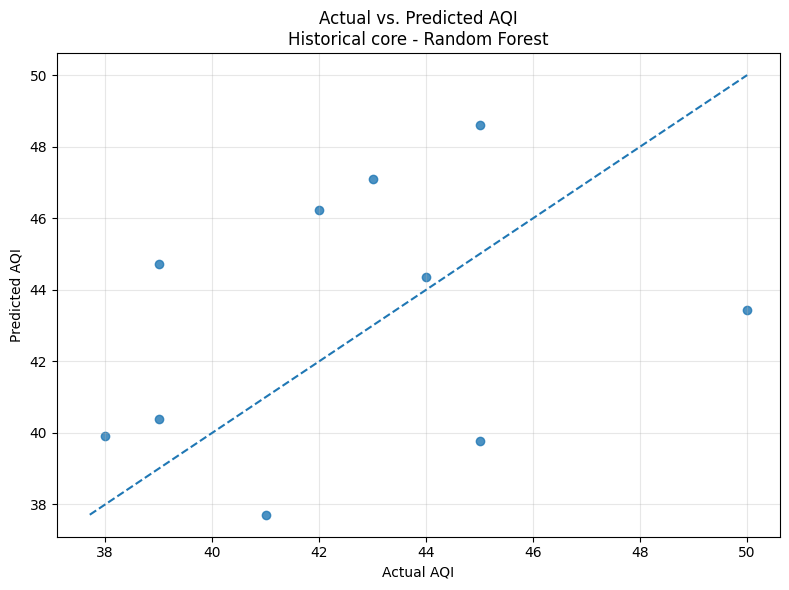

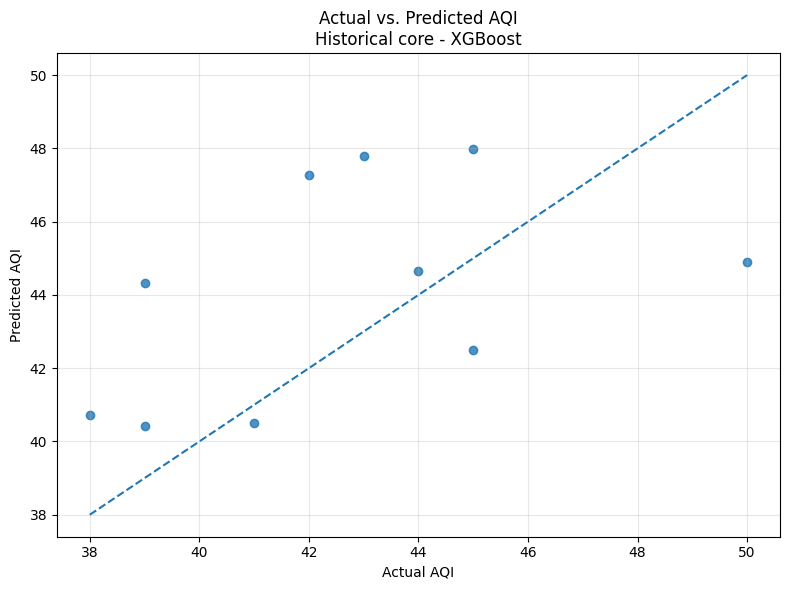

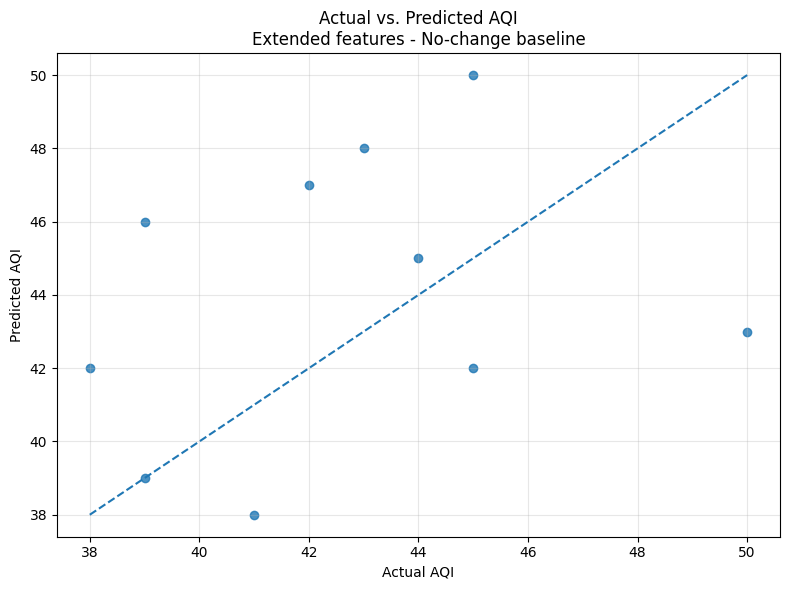

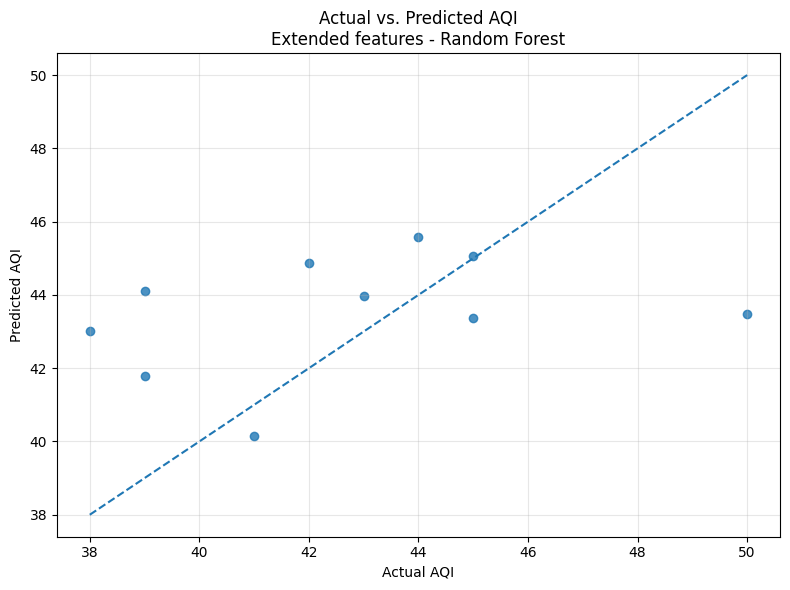

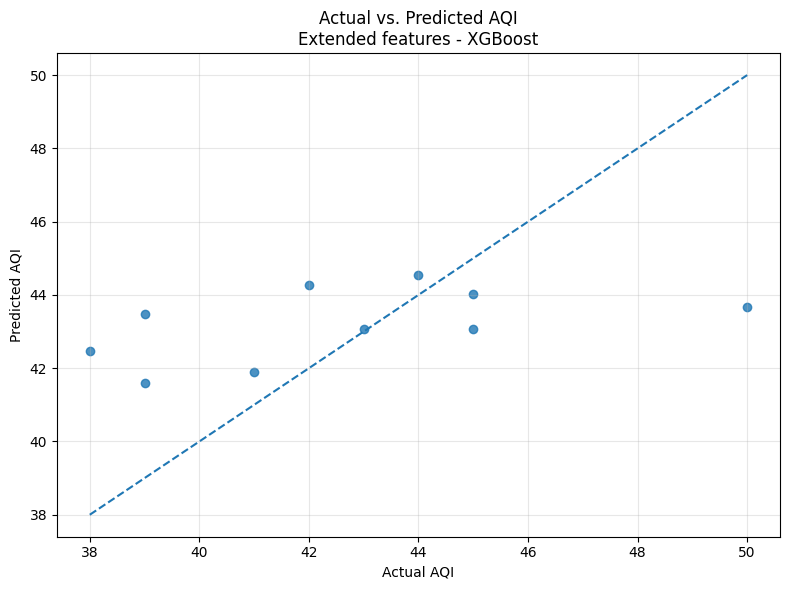

In [17]:
# ============================================================
# CELL 7: ACTUAL VS. PREDICTED AQI
# ============================================================

display(Markdown("## 6. Actual vs. Predicted AQI"))

display(Markdown("""
These plots compare predicted AQI values against the actual observed values.

Predictions closer to the diagonal reference line indicate better performance.
"""))

test_predictions = predictions[
    predictions["split"].str.lower() == "test"
].copy()

for experiment_name in test_predictions["experiment"].dropna().unique():

    experiment_data = test_predictions[
        test_predictions["experiment"] == experiment_name
    ]

    for model_name in experiment_data["model"].dropna().unique():

        model_data = experiment_data[
            experiment_data["model"] == model_name
        ]

        plt.figure(figsize=(8, 6))

        plt.scatter(
            model_data["actual_aqi"],
            model_data["predicted_aqi"],
            alpha=0.8
        )

        minimum = min(
            model_data["actual_aqi"].min(),
            model_data["predicted_aqi"].min()
        )

        maximum = max(
            model_data["actual_aqi"].max(),
            model_data["predicted_aqi"].max()
        )

        plt.plot(
            [minimum, maximum],
            [minimum, maximum],
            linestyle="--"
        )

        plt.title(
            f"Actual vs. Predicted AQI\n"
            f"{experiment_name} - {model_name}"
        )

        plt.xlabel("Actual AQI")
        plt.ylabel("Predicted AQI")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

## 7. Prediction Error Analysis


Residuals represent the difference between predicted and actual AQI.

- **Positive residual:** The model overpredicted AQI.
- **Negative residual:** The model underpredicted AQI.
- **Residuals closer to zero:** More accurate predictions.


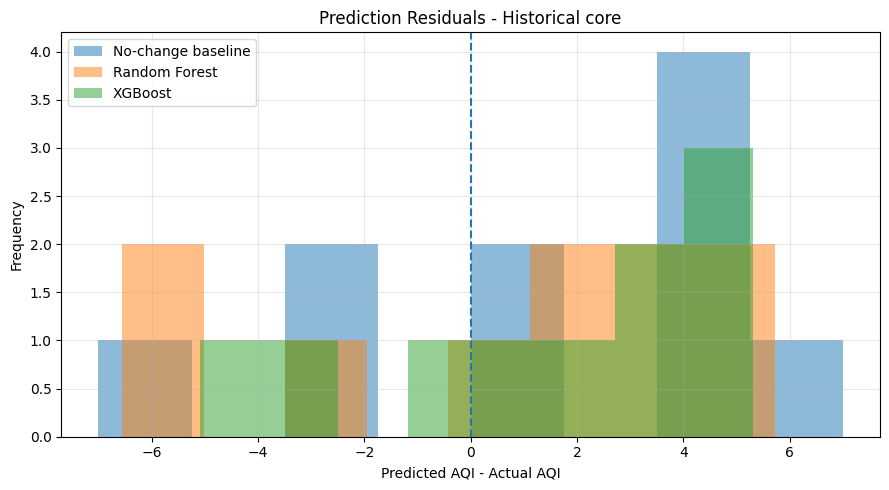

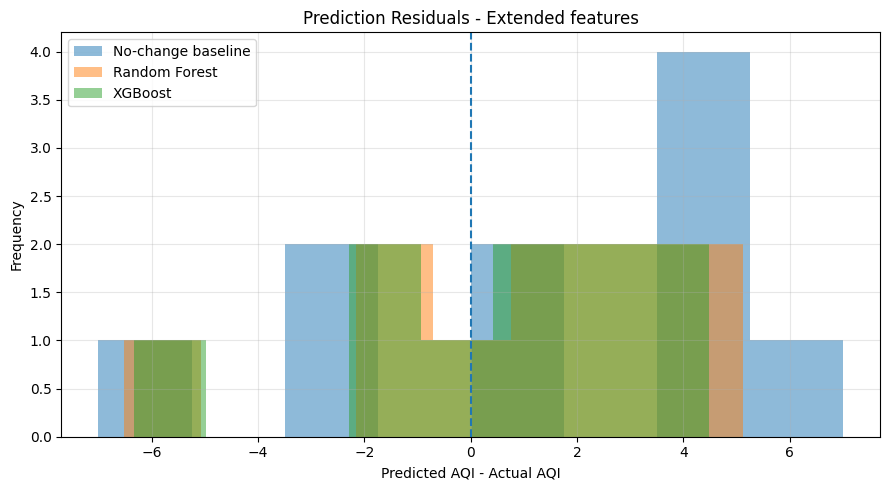

In [18]:
# ============================================================
# CELL 8: PREDICTION ERROR ANALYSIS
# ============================================================

display(Markdown("## 7. Prediction Error Analysis"))

display(Markdown("""
Residuals represent the difference between predicted and actual AQI.

- **Positive residual:** The model overpredicted AQI.
- **Negative residual:** The model underpredicted AQI.
- **Residuals closer to zero:** More accurate predictions.
"""))

test_predictions["residual"] = (
    test_predictions["predicted_aqi"]
    - test_predictions["actual_aqi"]
)

for experiment_name in test_predictions["experiment"].dropna().unique():

    experiment_data = test_predictions[
        test_predictions["experiment"] == experiment_name
    ]

    plt.figure(figsize=(9, 5))

    for model_name in experiment_data["model"].dropna().unique():

        model_data = experiment_data[
            experiment_data["model"] == model_name
        ]

        plt.hist(
            model_data["residual"],
            bins=8,
            alpha=0.5,
            label=model_name
        )

    plt.axvline(0, linestyle="--")

    plt.title(f"Prediction Residuals - {experiment_name}")
    plt.xlabel("Predicted AQI - Actual AQI")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. Feature Importance


Feature importance indicates which input variables contributed most to
the tree-based model predictions.

Higher importance does not necessarily mean that a feature causes changes
in AQI. It only describes its contribution within the trained model.


### extended_features_random_forest_feature_importance.csv

,feature,importance
0,last_observed_median_aqi,0.381402
1,weather_temp_mean_c,0.168016
2,recorded_tree_plantings,0.161705
3,drive_alone_pct,0.154518
4,campd_total_nox_mass_tons,0.087014
5,weather_precip_total_mm,0.047344


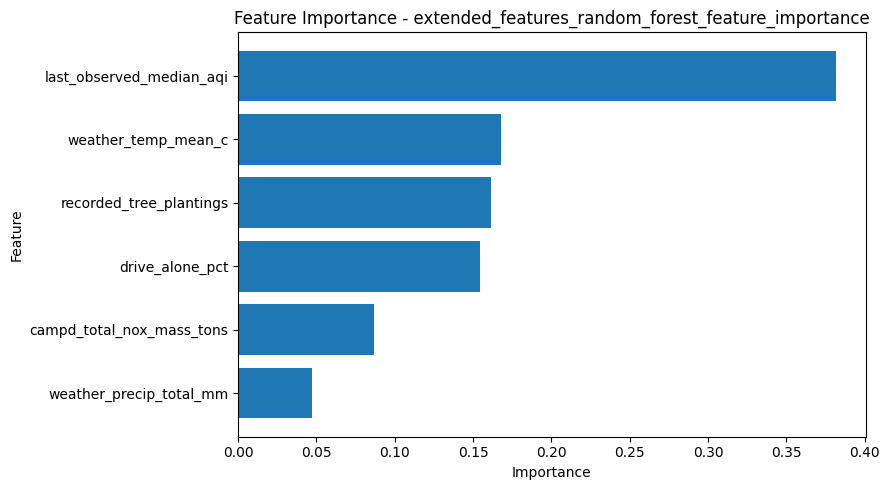

### extended_features_xgboost_feature_importance.csv

,feature,importance
0,last_observed_median_aqi,0.353164
1,weather_temp_mean_c,0.206231
2,drive_alone_pct,0.138876
3,weather_precip_total_mm,0.131528
4,campd_total_nox_mass_tons,0.098684
5,recorded_tree_plantings,0.071515


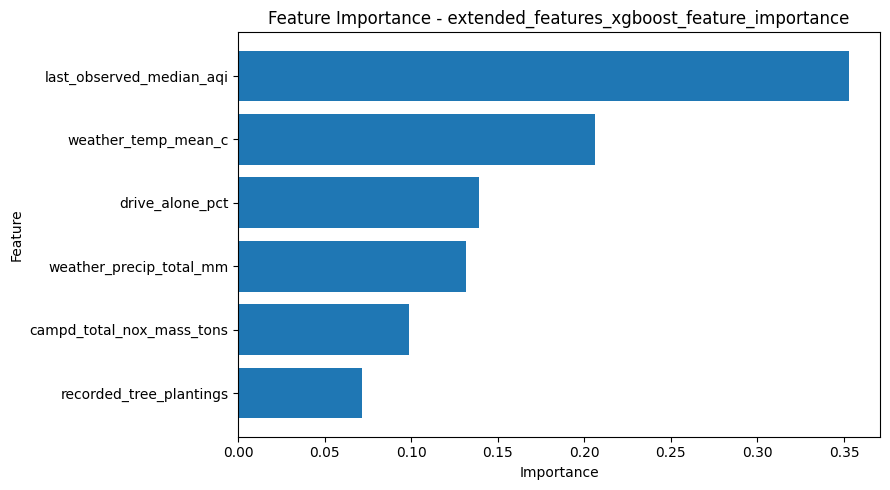

### historical_core_random_forest_feature_importance.csv

,feature,importance
0,last_observed_median_aqi,0.851815
1,campd_total_nox_mass_tons,0.079864
2,traffic_sample_mean_15min_vehicle_count,0.068321


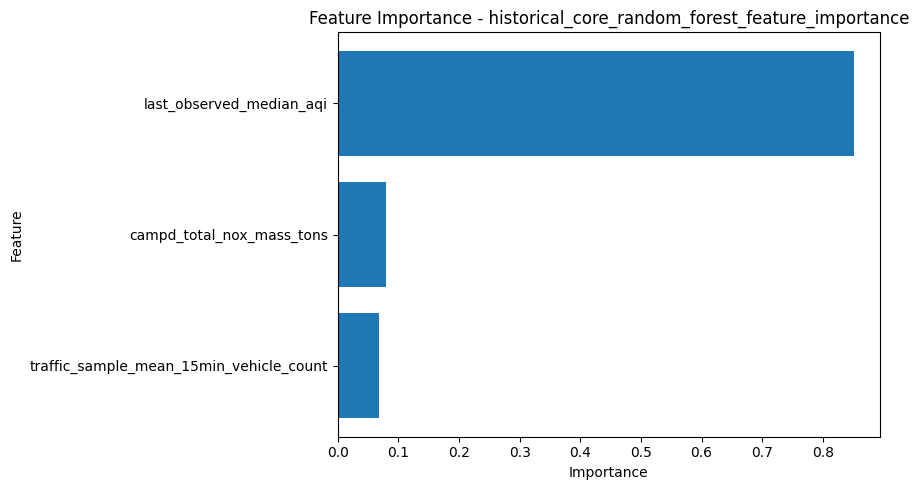

### historical_core_xgboost_feature_importance.csv

,feature,importance
0,last_observed_median_aqi,0.586500
1,campd_total_nox_mass_tons,0.309403
2,traffic_sample_mean_15min_vehicle_count,0.104097


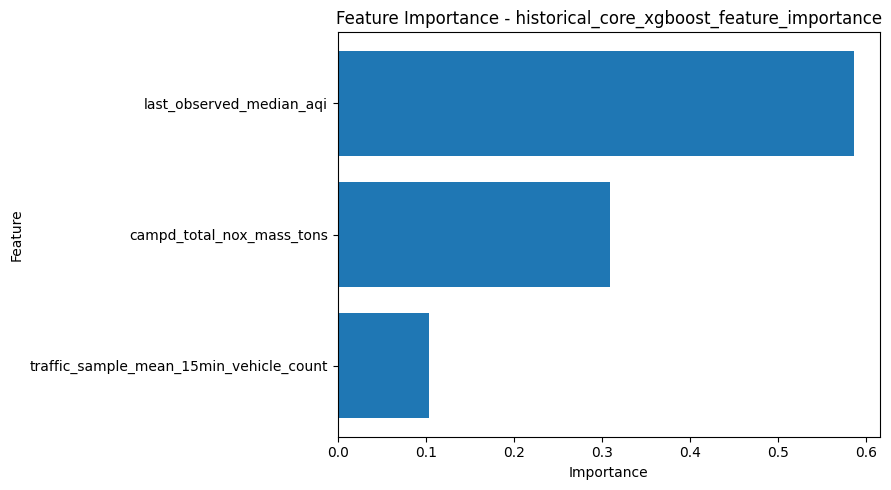

In [19]:
# ============================================================
# CELL 9: FEATURE IMPORTANCE
# ============================================================

display(Markdown("## 8. Feature Importance"))

display(Markdown("""
Feature importance indicates which input variables contributed most to
the tree-based model predictions.

Higher importance does not necessarily mean that a feature causes changes
in AQI. It only describes its contribution within the trained model.
"""))

importance_files = list(BASE_DIR.glob("*importance*.csv"))

if importance_files:

    for file in importance_files:

        importance = pd.read_csv(file)

        display(Markdown(f"### {file.name}"))
        display(importance)

        if {"feature", "importance"}.issubset(importance.columns):

            importance = importance.sort_values(
                "importance",
                ascending=True
            )

            plt.figure(figsize=(9, 5))

            plt.barh(
                importance["feature"],
                importance["importance"]
            )

            plt.title(f"Feature Importance - {file.stem}")
            plt.xlabel("Importance")
            plt.ylabel("Feature")
            plt.tight_layout()
            plt.show()

else:
    print("No feature importance CSV files were found.")

In [20]:
# ============================================================
# CELL 10: OVERALL FINDINGS AND CONCLUSION
# ============================================================

display(Markdown("## 9. Overall Findings"))

display(Markdown("""
### Model Performance

The evaluation results show that the tree-based models can outperform
the no-change baseline, although performance varies between experiments
and forecast years.

The extended XGBoost model achieved the lowest fixed-test MAE, while the
extended Random Forest achieved the lowest extended rolling-backtest MAE.
The historical XGBoost model achieved the strongest rolling-backtest R²
among the historical models.

### Limitations

1. The dataset contains a relatively small number of borough-year observations.
2. Performance varies across boroughs and forecast years.
3. Validation results are not consistently strong across experiments.
4. The evaluation results do not establish that the models will generalize
   equally well to future years.
5. Borough-level metrics are based on limited observations.

### Conclusion

The results indicate that machine learning models can provide useful
next-year AQI estimates for NYC boroughs. However, the models should be
treated as experimental forecasting tools rather than highly reliable
long-term predictors.

Additional historical data, improved features, and evaluation across
more forecast years would help establish whether the observed improvements
over the baseline are consistent.
"""))

## 9. Overall Findings


### Model Performance

The evaluation results show that the tree-based models can outperform
the no-change baseline, although performance varies between experiments
and forecast years.

The extended XGBoost model achieved the lowest fixed-test MAE, while the
extended Random Forest achieved the lowest extended rolling-backtest MAE.
The historical XGBoost model achieved the strongest rolling-backtest R²
among the historical models.

### Limitations

1. The dataset contains a relatively small number of borough-year observations.
2. Performance varies across boroughs and forecast years.
3. Validation results are not consistently strong across experiments.
4. The evaluation results do not establish that the models will generalize
   equally well to future years.
5. Borough-level metrics are based on limited observations.

### Conclusion

The results indicate that machine learning models can provide useful
next-year AQI estimates for NYC boroughs. However, the models should be
treated as experimental forecasting tools rather than highly reliable
long-term predictors.

Additional historical data, improved features, and evaluation across
more forecast years would help establish whether the observed improvements
over the baseline are consistent.


In [22]:
# ============================================================
# CELL 11: BEST MODEL BY MAE
# ============================================================

display(Markdown("## 10. Best Model by MAE"))

best_models = (
    summary.sort_values(
        ["experiment", "split", "MAE"]
    )
    .groupby(["experiment", "split"])
    .head(1)
    .reset_index(drop=True)
)

display(
    best_models[
        [
            "experiment",
            "split",
            "model",
            "n_rows",
            "MAE",
            "RMSE",
            "R2",
            "MAE_improvement_vs_baseline_pct"
        ]
    ]
)

print("Analysis complete.")

## 10. Best Model by MAE

,experiment,split,model,n_rows,MAE,RMSE,R2,MAE_improvement_vs_baseline_pct
0,Extended features,rolling_backtest,Random Forest,15.0,2.975969,3.555117,0.083846,20.286555
1,Extended features,test,XGBoost,10.0,2.461100,3.130784,0.172145,38.472509
2,Extended features,validation,No-change baseline,5.0,3.200000,3.346640,-0.590909,0.000000
3,Historical core,rolling_backtest,XGBoost,30.0,3.078515,3.724481,0.128415,10.334507
4,Historical core,test,XGBoost,10.0,3.127158,3.610051,-0.100715,21.821051
5,Historical core,validation,XGBoost,10.0,2.002544,2.264654,0.403645,8.975272


Analysis complete.
